# Chroma, Pitch, and Tempo

The music editor of the radio station wants upbeat songs at about 120 beats per minute,
preferably in a minor key, for a new playlist. The perceptual features of demo ch11-01 say how
bright or how loud a piece is, but not which notes it plays, in which key, or how fast. This
notebook follows the book section *Musical Features*: it maps frequencies to notes, computes the
chroma of the Brahms clip and estimates its key, follows the melody of a trumpet loop with two
pitch estimators, and derives the tempo from the onsets. At the end, we answer the editor's
request for four music recordings.

**Learning goals:**
- Convert between frequencies, note numbers, pitch classes, and octaves
- Compute a chroma vector and estimate the key of a recording with key profiles
- Estimate the fundamental frequency with a harmonic sum and with the autocorrelation
- Compute the onset strength, estimate the tempo from its autocorrelation, and recognize octave errors
- Track the beats of a recording

**Prerequisites:** demo ch11-01 (spectrogram, frames, mel spectrum)

**Data:** four librosa example recordings: the Brahms clip of demo ch11-01, a trumpet loop
recorded at 90 bpm, Tchaikovsky's Dance of the Sugar Plum Fairy, and the jazz piece Vibe Ace.
They are downloaded on the first run (a few MB each) into the librosa cache.

## Setup

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import librosa
from IPython.display import Audio

from shared.display import print_table, display_md
from ch11_audio import SR, CLIPS, MUSIC_C, load, credits, stft_db, show_spectrogram

music = load("brahms")                                  # 45.8 s at 22,050 Hz
PITCH = ["C", "C♯", "D", "E♭", "E", "F", "F♯", "G", "G♯", "A", "B♭", "B"]

## 1. Notes and Frequencies

Doubling the frequency raises a note by one octave, and Western music divides the octave into 12
semitones. With the standard pitch A4 = 440 Hz and one note number $m$ per semitone ($m = 69$ for
A4), every note has a frequency, and every frequency a note:

$$
f(m) = 440 \cdot 2^{(m - 69)/12}, \qquad m(f) = 69 + 12 \cdot \log_2\left(\frac{f}{440}\right)
$$

The pitch class is $p = \text{round}(m(f)) \bmod 12$, and the octave is
$\lfloor \text{round}(m(f)) / 12 \rfloor - 1$.

In [2]:
note_freq = lambda m: 440 * 2 ** ((m - 69) / 12)
note_number = lambda f: 69 + 12 * np.log2(np.asarray(f, float) / 440)

def note_name(f):
    m = int(np.round(note_number(f)))
    return f"{PITCH[m % 12]}{m // 12 - 1}"

print_table(
    [[f"{f:g} Hz", f"{note_number(f):.2f}", int(np.round(note_number(f))) % 12, note_name(f)]
     for f in (note_freq(60), 784, 270)],
    headers=["Frequency", "Note number m(f)", "Pitch class", "Note"],
)

| Frequency   |   Note number m(f) |   Pitch class | Note   |
|:------------|-------------------:|--------------:|:-------|
| 261.626 Hz  |              60    |             0 | C4     |
| 784 Hz      |              79    |             7 | G5     |
| 270 Hz      |              60.55 |             1 | C♯4    |

Middle C has 261.63 Hz. A partial at 784 Hz is G5, and 270 Hz, between C4 and C♯4, rounds to C♯4.

An instrument does not play one sine wave. A note at $f_0 = 220$ Hz has partials at integer
multiples of $f_0$, the harmonics. Their note names show that a single note puts energy into
several pitch classes:

In [3]:
print_table([[h, f"{h * 220:,} Hz", note_name(h * 220), f"{note_number(h * 220) - round(note_number(h * 220)):+.2f}"]
             for h in range(1, 9)],
            headers=["Harmonic", "Frequency", "Nearest note", "Distance (semitones)"])

|   Harmonic | Frequency   | Nearest note   |   Distance (semitones) |
|-----------:|:------------|:---------------|-----------------------:|
|          1 | 220 Hz      | A3             |                   0    |
|          2 | 440 Hz      | A4             |                   0    |
|          3 | 660 Hz      | E5             |                   0.02 |
|          4 | 880 Hz      | A5             |                   0    |
|          5 | 1,100 Hz    | C♯6            |                  -0.14 |
|          6 | 1,320 Hz    | E6             |                   0.02 |
|          7 | 1,540 Hz    | G6             |                  -0.31 |
|          8 | 1,760 Hz    | A6             |                   0    |

The octaves of A dominate, but the third and sixth harmonics land on E, and the fifth near C♯:
the notes of an A major chord. This is worth keeping in mind for the chroma below.

## 2. Chroma

A chroma vector says which pitch classes sound in a frame, regardless of the octave. Each bin is
assigned to the pitch class of its frequency, and the energy of all bins with the same class is
summed:

$$
h(t, p) = \frac{\sum_{k \,:\, p(k) = p} |X(t,k)|^2}{\sum_{k} |X(t,k)|^2}, \qquad 0 \le p \le 11
$$

Low notes lie only a few hertz apart, so chroma needs long frames. As in the book, we use frames of
8192 samples (372 ms, a bin spacing of 2.7 Hz) and only the bins between 55 and 4000 Hz.

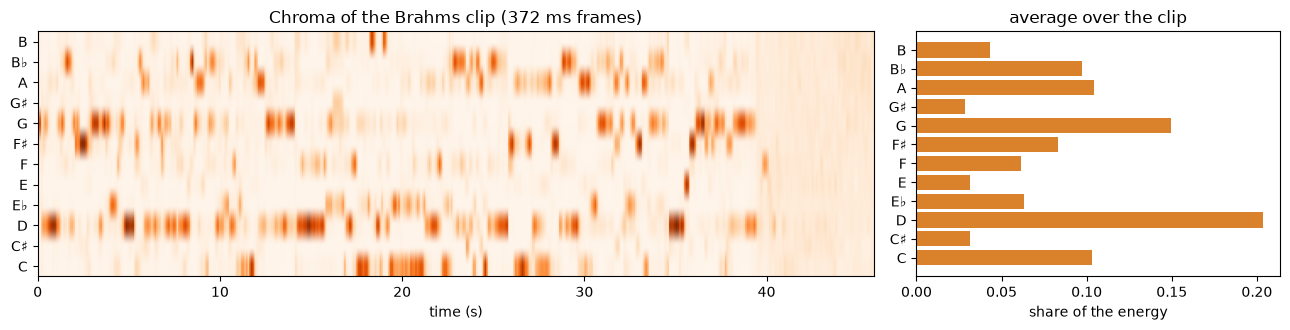

Largest shares: D 0.20, G 0.15, A 0.10, C 0.10, B♭ 0.10, F♯ 0.08; smallest: C♯ 0.03, E 0.03, G♯ 0.03

In [4]:
def chroma(y, n=8192, hop=2048, f_lo=55, f_hi=4000):
    S = np.abs(librosa.stft(y, n_fft=n, hop_length=hop)) ** 2       # bins x frames
    f = np.arange(S.shape[0]) * SR / n
    keep = (f >= f_lo) & (f <= f_hi)
    pc = np.round(note_number(f[keep])).astype(int) % 12              # pitch class of each bin
    H = np.array([S[keep][pc == p].sum(axis=0) for p in range(12)])   # 12 x frames
    return H / H.sum(axis=0, keepdims=True)

H = chroma(music)
avg = H.mean(axis=1)                                    # average chroma of the whole clip

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.4), gridspec_kw=dict(width_ratios=[2.3, 1]))
a1.imshow(H, aspect="auto", origin="lower", cmap="Oranges", extent=(0, H.shape[1] * 2048 / SR, -0.5, 11.5))
a1.set(yticks=range(12), yticklabels=PITCH, xlabel="time (s)", title="Chroma of the Brahms clip (372 ms frames)")
a2.barh(range(12), avg, color=MUSIC_C)
a2.set(yticks=range(12), yticklabels=PITCH, xlabel="share of the energy", title="average over the clip")
fig.tight_layout()
plt.show()

order = np.argsort(avg)[::-1]
display_md("Largest shares: " + ", ".join(f"{PITCH[p]} {avg[p]:.2f}" for p in order[:6])
           + "; smallest: " + ", ".join(f"{PITCH[p]} {avg[p]:.2f}" for p in order[-3:]))

D and G dominate, while C♯, E, and G♯ get almost nothing. The chroma changes from passage to
passage as the harmony moves.

## 3. The Key of the Brahms Clip

A key profile is a template of 12 values that says how prominent each pitch class is in a key.
We use the profiles of Krumhansl and Kessler for C major and C minor, rotate them to all 12
tonics, and correlate the average chroma with each of the 24 profiles.

In [5]:
MAJOR = np.array([6.35, 2.23, 3.48, 2.33, 4.38, 4.09, 2.52, 5.19, 2.39, 3.66, 2.29, 2.88])
MINOR = np.array([6.33, 2.68, 3.52, 5.38, 2.60, 3.53, 2.54, 4.75, 3.98, 2.69, 3.34, 3.17])

def key_scores(avg):
    """Correlation of a chroma vector with all 24 key profiles, best first."""
    scores = [(np.corrcoef(avg, np.roll(profile, k))[0, 1], f"{PITCH[k]} {mode}")
              for profile, mode in ((MAJOR, "major"), (MINOR, "minor")) for k in range(12)]
    return sorted(scores, reverse=True)

ranked = key_scores(avg)
names = [k for _, k in ranked]
print_table([[i + 1, k, f"{r:.2f}"] for i, (r, k) in enumerate(ranked[:3])]
            + [[names.index("F♯ minor") + 1, "F♯ minor", f"{ranked[names.index('F♯ minor')][0]:.2f}"]],
            headers=["Rank", "Key", "Correlation"])
display_md(f"File name of the recording: `{os.path.basename(librosa.ex('brahms'))}`")

|   Rank | Key      |   Correlation |
|-------:|:---------|--------------:|
|      1 | G minor  |          0.76 |
|      2 | G major  |          0.67 |
|      3 | D major  |          0.66 |
|     13 | F♯ minor |         -0.04 |

File name of the recording: `Hungarian_Dance_number_5_-_Allegro_in_F_sharp_minor_(string_orchestra).ogg`

The best match is G minor. Its tonic G, minor third B♭, fifth D, and leading tone F♯ are all among
the six largest shares, and every G adds its third harmonic to D. The file name says F♯ minor, the
key of Brahms's original piano version, but the fifth of F♯ minor, C♯, is one of the smallest
shares. The string orchestra plays the dance in G minor. The content contradicts the metadata: a
title typed into a catalogue can be wrong, while the chroma is measured on the recording itself.

## 4. Fundamental Frequency

Chroma records all pitch classes, including those of the harmonics, but not the melody. For the
melody, we estimate the fundamental $f_0$ of each frame. The trumpet loop plays one note at a time.

In [6]:
trumpet = load("trumpet")
Audio(trumpet, rate=SR)

The **harmonic sum** tries every candidate $f_0$, adds up the magnitudes of the spectrum at
$f_0, 2f_0, 3f_0, \dots$, and chooses the candidate that collects the most. Giving the higher
harmonics less weight, here $1/h$ for harmonic $h$, keeps the estimate from jumping to half the
true pitch. The **autocorrelation** works in the time domain: a periodic signal resembles itself
when shifted by one period, so the shift $l$ with the highest correlation gives $f_0 = f_s / l$.
We use frames of 2048 samples (93 ms) and candidates between 100 and 1000 Hz.

In [7]:
n, hop = 2048, 512
F = librosa.util.frame(trumpet, frame_length=n, hop_length=hop).T     # frames x samples
X = np.abs(np.fft.rfft(F * np.hanning(n), axis=1))
f_bins = np.arange(X.shape[1]) * SR / n
cands = np.arange(100, 1001)                            # candidate f0 in steps of 1 Hz

def harmonic_sum(x, harmonics=8):
    score = sum(np.interp(h * cands, f_bins, x) / h for h in range(1, harmonics + 1))
    return cands[np.argmax(score)]

def autocorrelation(frame):
    x = frame - frame.mean()
    r = np.correlate(x, x, mode="full")[len(x) - 1:]    # r(l) for l = 0, 1, ...
    lo, hi = SR // 1000, SR // 100                      # lags for 1000 Hz down to 100 Hz
    return SR / (lo + np.argmax(r[lo:hi]))

f0_sum = np.array([harmonic_sum(x) for x in X])
f0_acf = np.array([autocorrelation(fr) for fr in F])

As a reference, librosa's pYIN estimator, a refined autocorrelation method with a model of note
transitions, decides which frames contain a note and estimates their pitch. We compare the two
simple estimators with it on the frames where pYIN hears a note.

In [8]:
f0_ref, voiced, _ = librosa.pyin(trumpet, fmin=100, fmax=1000, sr=SR, frame_length=n,
                                 hop_length=hop, center=False)
m = min(len(f0_ref), len(F))
v = voiced[:m]
cents = lambda est: 1200 * np.abs(np.log2(est[:m][v] / f0_ref[:m][v]))  # distance in cents (1/100 semitone)

print_table(
    [[name, f"{np.mean(cents(est) < 50):.0%}", f"{np.mean(np.abs(cents(est) - 1200) < 50):.0%}"]
     for name, est in (("harmonic sum", f0_sum), ("autocorrelation", f0_acf))],
    headers=[f"Estimator ({v.sum()} frames with a note)", "same note as pYIN", "one octave off"],
)

| Estimator (186 frames with a note)   | same note as pYIN   | one octave off   |
|:-------------------------------------|:--------------------|:-----------------|
| harmonic sum                         | 91%                 | 4%               |
| autocorrelation                      | 96%                 | 2%               |

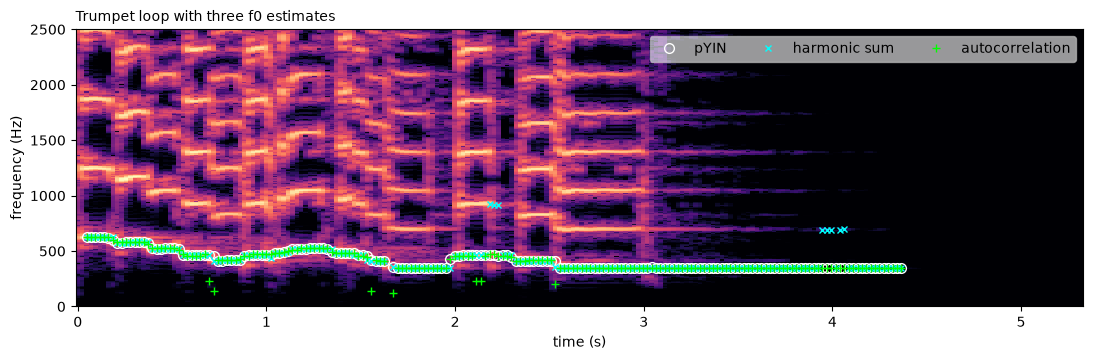

Notes of the melody according to pYIN, in order: E♭5 D5 C♯5 C5 B♭4 G♯4 B♭4 B4 C5 B4 B♭4 A4 G♯4 F4 A4 B♭4 A4 G♯4 F4

In [9]:
S, n_s, hop_s = stft_db(trumpet, 93, 23.2)
t = (np.arange(m) * hop + n / 2) / SR                   # frame centers
fig, ax = plt.subplots(figsize=(13, 3.6))
show_spectrogram(ax, S, n_s, hop_s, f_max=2500, title="Trumpet loop with three f0 estimates")
ax.plot(t[v], f0_ref[:m][v], "o", color="white", ms=7, mfc="none", label="pYIN")
ax.plot(t[v], f0_sum[:m][v], "x", color="cyan", ms=5, label="harmonic sum")
ax.plot(t[v], f0_acf[:m][v], "+", color="lime", ms=6, label="autocorrelation")
ax.legend(loc="upper right", ncol=3, framealpha=0.6)
plt.show()

notes = [note_name(f) for f in f0_ref[:m][v]]
display_md("Notes of the melody according to pYIN, in order: "
           + " ".join(x for i, x in enumerate(notes) if i == 0 or x != notes[i - 1]))

The simple estimators follow the melody in almost all frames. Their few errors lie at note
changes, where a frame mixes two pitches, and in the fading end of the last note, where the
harmonic sum jumps to a harmonic and the autocorrelation drops to a lower pitch. Polyphonic music, with
several notes at once, needs an iteration: estimate one fundamental, remove its harmonics from the
spectrum, and repeat. The book's appendix describes it.

## 5. Onset Strength

The tempo is measured in beats per minute (bpm). Beats show up as note onsets: sudden increases of
energy in some frequency bands. The onset strength sums the positive part of the change in the log
mel spectrum:

$$
o(t) = \sum_{b=1}^{B} \max\bigl(0,\ \log M(t,b) - \log M(t-1,b)\bigr)
$$

Only increases count, because a note that starts matters for the beat and one that fades does not.
We use 128 mel bands and a hop of $H = 512$ samples, so one onset frame lasts 23.2 ms. A floor at
80 dB below the loudest point keeps the logarithm of near-silent bands from producing noise.

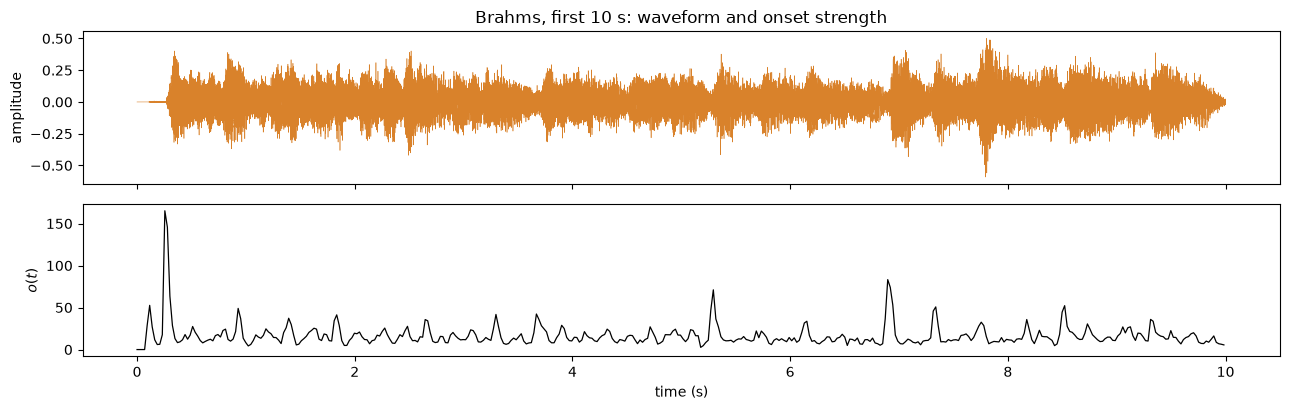

In [10]:
H_ONSET = 512
Mel = librosa.feature.melspectrogram(y=music, sr=SR, n_fft=2048, hop_length=H_ONSET)   # 128 x frames
logM = np.log10(np.maximum(Mel, Mel.max() * 1e-8))     # floor 80 dB below the maximum
o = np.r_[0, np.maximum(0, np.diff(logM, axis=1)).sum(axis=0)]

t_o = np.arange(len(o)) * H_ONSET / SR
k = t_o < 10
fig, axes = plt.subplots(2, 1, figsize=(13, 4.2), sharex=True)
axes[0].plot(np.arange(10 * SR) / SR, music[:10 * SR], color=MUSIC_C, lw=0.4)
axes[0].set(ylabel="amplitude", title="Brahms, first 10 s: waveform and onset strength")
axes[1].plot(t_o[k], o[k], color="black", lw=0.9)
axes[1].set(ylabel="$o(t)$", xlabel="time (s)")
fig.tight_layout()
plt.show()

## 6. Tempo from the Onset Autocorrelation

The tempo is the period at which the peaks of $o(t)$ repeat. The autocorrelation
$R(l) = \sum_t o(t) \cdot o(t + l)$ is large for lags $l$ at which the onset pattern lines up with
a shifted copy of itself. A lag of $l$ onset frames lasts $l \cdot H / f_s$ seconds:

$$
\text{tempo} = \frac{60 \cdot f_s}{H \cdot l_0} \ \text{bpm}, \qquad l_0 = \arg\max_{l} R(l)
$$

We restrict the lags to tempos between 40 and 240 bpm.

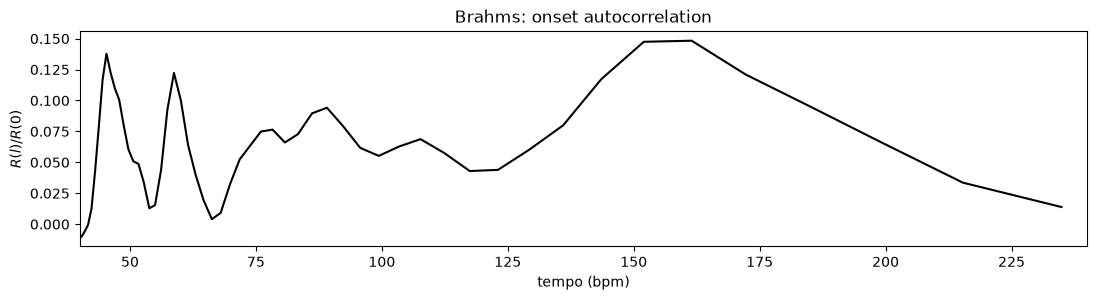

|   Lag l (frames) |   Tempo (bpm) |   R(l) / R(0) |
|-----------------:|--------------:|--------------:|
|               16 |         161.5 |          0.15 |
|               17 |         152   |          0.15 |
|               57 |          45.3 |          0.14 |
|               56 |          46.1 |          0.12 |
|               44 |          58.7 |          0.12 |

With librosa's onset strength (decibels and the mean over the bands instead of the sum): lag 17 (152.0 bpm), lag 16 (161.5 bpm), lag 57 (45.3 bpm)

In [11]:
def tempo_peaks(o, top=5):
    x = o - o.mean()
    R = np.correlate(x, x, mode="full")[len(x) - 1:]
    lags = np.arange(1, len(R))
    bpm = 60 * SR / (H_ONSET * lags)
    ok = (bpm >= 40) & (bpm <= 240)
    lags, bpm, r = lags[ok], bpm[ok], R[1:][ok] / R[0]
    best = np.argsort(r)[::-1][:top]
    return lags, bpm, r, [(int(lags[i]), float(bpm[i]), float(r[i])) for i in best]

lags, bpm, r, best = tempo_peaks(o)
librosa_best = tempo_peaks(librosa.onset.onset_strength(y=music, sr=SR, hop_length=H_ONSET))[3]

fig, ax = plt.subplots(figsize=(13, 2.8))
ax.plot(bpm, r, color="black")
ax.set(xlabel="tempo (bpm)", ylabel="$R(l) / R(0)$", title="Brahms: onset autocorrelation", xlim=(40, 240))
plt.show()
print_table([[lag, f"{b:.1f}", f"{v:.2f}"] for lag, b, v in best],
            headers=["Lag l (frames)", "Tempo (bpm)", "R(l) / R(0)"])
display_md("With librosa's onset strength (decibels and the mean over the bands instead of the sum): "
           + ", ".join(f"lag {lag} ({b:.1f} bpm)" for lag, b, _ in librosa_best[:3]))

Lags 16 and 17 are almost equally strong: the true beat period lies between them, at about 395 ms.
Lag 17 gives $60 \cdot 22{,}050 / (512 \cdot 17) = 152.0$ bpm, the tempo the book reports. The peaks
near 45 bpm are three beats long, one bar of the dance.

The trumpet loop was recorded at 90 bpm.

In [12]:
o_tr = librosa.onset.onset_strength(y=trumpet, sr=SR, hop_length=H_ONSET)
best_tr = tempo_peaks(o_tr, top=8)[3]
print_table([[lag, f"{b:.1f}", f"{v:.2f}", f"{b / 90:.2f}"] for lag, b, v in best_tr],
            headers=["Lag l", "Tempo (bpm)", "R(l) / R(0)", "Ratio to 90 bpm"])

|   Lag l |   Tempo (bpm) |   R(l) / R(0) |   Ratio to 90 bpm |
|--------:|--------------:|--------------:|------------------:|
|      14 |         184.6 |          0.39 |              2.05 |
|      21 |         123   |          0.32 |              1.37 |
|      22 |         117.5 |          0.32 |              1.31 |
|      15 |         172.3 |          0.3  |              1.91 |
|      16 |         161.5 |          0.26 |              1.79 |
|      27 |          95.7 |          0.25 |              1.06 |
|      13 |         198.8 |          0.24 |              2.21 |
|      62 |          41.7 |          0.23 |              0.46 |

The strongest peak, at lag 14, gives about twice the true tempo, while lag 27 gives a value close
to 90 bpm with a weaker peak. Such octave errors, at double, half, or a third of the true tempo, are
the typical failure of tempo estimation. Estimators therefore prefer tempos near 120 bpm, and
listeners themselves often disagree whether a piece moves at 90 or at 180 bpm.

## 7. Beat Tracking

Beat tracking places the individual beats in time, the moments at which a listener would tap
along. The beats should coincide with strong onsets and follow each other at intervals close to
the estimated period. librosa implements the dynamic program of Ellis (2007).

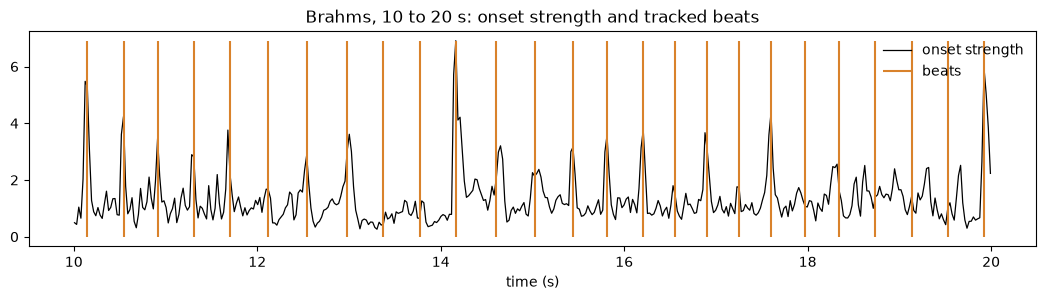

Tempo **152.0 bpm**, 101 beats, median distance **395 ms**. Listen to the excerpt with a click on each beat:

In [13]:
tempo, beats = librosa.beat.beat_track(y=music, sr=SR, hop_length=H_ONSET)
beat_times = librosa.frames_to_time(beats, sr=SR, hop_length=H_ONSET)

o_lib = librosa.onset.onset_strength(y=music, sr=SR, hop_length=H_ONSET)
t_lib = librosa.frames_to_time(np.arange(len(o_lib)), sr=SR, hop_length=H_ONSET)
a, b = 10, 20                                           # a ten-second excerpt
fig, ax = plt.subplots(figsize=(13, 2.8))
sel = (t_lib >= a) & (t_lib < b)
ax.plot(t_lib[sel], o_lib[sel], color="black", lw=0.9, label="onset strength")
ax.vlines(beat_times[(beat_times >= a) & (beat_times < b)], 0, o_lib[sel].max(), color=MUSIC_C, lw=1.5, label="beats")
ax.set(xlabel="time (s)", title="Brahms, 10 to 20 s: onset strength and tracked beats")
ax.legend(loc="upper right", frameon=False)
plt.show()

display_md(f"Tempo **{float(np.atleast_1d(tempo)[0]):.1f} bpm**, {len(beats)} beats, median distance "
           f"**{np.median(np.diff(beat_times)) * 1000:.0f} ms**. Listen to the excerpt with a click on each beat:")
clicks = librosa.clicks(times=beat_times[(beat_times >= a) & (beat_times < b)] - a, sr=SR, length=(b - a) * SR)
Audio(music[a * SR:b * SR] + 0.5 * clicks, rate=SR)

The onsets often fall on the beats, but also between them and with varying strength. The dynamic
program places the beats where onsets and a regular period agree.

## Payoff: The Music Editor's Playlist

The editor wants upbeat songs at about 120 bpm, preferably in a minor key. We estimate the tempo
and the key of the four music recordings and check them against the request, here 100 to 140 bpm.

In [14]:
rows = []
for name in ("brahms", "nutcracker", "vibeace", "trumpet"):
    y = load(name)
    bpm_est = float(np.atleast_1d(librosa.beat.beat_track(y=y, sr=SR)[0])[0])
    (r1, key1), (r2, key2) = key_scores(chroma(y).mean(axis=1))[:2]
    fits = 100 <= bpm_est <= 140 and key1.endswith("minor")
    rows.append([CLIPS[name][0], f"{bpm_est:.1f}", f"{bpm_est / 2:.1f} / {bpm_est * 2:.1f}",
                 f"{key1} ({r1:.2f})", f"{key2} ({r2:.2f})", "yes" if fits else "no"])
print_table(rows, headers=["Recording", "Tempo (bpm)", "Half / double", "Best key", "Second key", "Fits"])

| Recording                                  |   Tempo (bpm) | Half / double   | Best key       | Second key     | Fits   |
|:-------------------------------------------|--------------:|:----------------|:---------------|:---------------|:-------|
| Brahms, Hungarian Dance No. 5              |         152   | 76.0 / 304.0    | G minor (0.76) | G major (0.67) | no     |
| Tchaikovsky, Dance of the Sugar Plum Fairy |         107.7 | 53.8 / 215.3    | E minor (0.81) | B minor (0.65) | yes    |
| Vibe Ace (jazz)                            |          64.6 | 32.3 / 129.2    | E major (0.75) | E minor (0.69) | no     |
| Trumpet loop (90 bpm)                      |         184.6 | 92.3 / 369.1    | F major (0.81) | F minor (0.76) | no     |

<div style="border-left: 4px solid #C8102E; background: rgba(200, 16, 46, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#C8102E; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">Musical features turn audio into playlist facets</strong><br>
Tempo and key become filterable fields, just like a year or a genre in the metadata, but measured on the recording itself. Each estimate needs a sanity check: the tempo can be off by an octave, and the key by a related key that shares most of its notes. A tempo of 64.6 bpm may well be a piece at 129 bpm; the half and double tempos show which recordings sit near the boundary.
</div>

## Summary

- Note numbers turn frequencies into notes: $m(f) = 69 + 12 \log_2(f / 440)$, pitch class
  $m \bmod 12$. Harmonics of one note fall on several pitch classes.
- Chroma sums the energy per pitch class over all octaves. It needs long frames, captures harmony,
  and a correlation with key profiles estimates the key, even when the metadata says otherwise.
- The harmonic sum and the autocorrelation estimate the fundamental of a single melody; they fail
  at note boundaries and in polyphonic music.
- The onset strength measures the increases of energy; its autocorrelation gives the tempo, with
  octave errors as the typical failure. Beat tracking places the beats with dynamic programming.

## Try it yourself

1. **Shorter chroma frames.** Compute the average chroma of the Brahms clip with `n=1024` (46 ms)
   and estimate the key again. What happens to the correlation of G minor?
2. **Harmonic weights.** Give all harmonics the same weight in `harmonic_sum` and compare with pYIN
   again. Do the octave errors increase?
3. **A tempo prior.** Multiply $R(l)$ with a weight that prefers tempos near 120 bpm, for example
   $\exp(-\tfrac{1}{2} \log_2(\text{bpm}/120)^2)$, and estimate the tempo of the trumpet loop again.

## Credits

In [15]:
print_table(credits(["brahms", "trumpet", "nutcracker", "vibeace"]), headers=["Clip", "Title", "Attribution", "License"])

| Clip       | Title                         | Attribution                                             | License    |
|:-----------|:------------------------------|:--------------------------------------------------------|:-----------|
| brahms     | Hungarian Dance number 5      | Johannes Brahms (composer), US Army Strings (performer) | CC-PDM-1.0 |
| trumpet    | solo trumpet 06               | Mihai Sorohan                                           | CC-BY-4.0  |
| nutcracker | Dance of the Sugar Plum Fairy | P.I. Tchaikovsky (composer), Kevin MacLeod (arranger)   | CC-BY-4.0  |
| vibeace    | Vibe Ace                      | Kevin MacLeod                                           | CC-BY-4.0  |